# 2.5 Υπολογισμός μετρικών αξιολόγησης

In [ ]:
!pip install -q "transformers<5" evaluate sacrebleu unbabel-comet

In [10]:
import gc
import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import evaluate
import matplotlib.pyplot as plt
import pandas as pd
import torch
from huggingface_hub import login

## Φόρτωση δεδομένων

In [11]:
# FLORES
with open("facebook_nllb_200_translations.txt", "r", encoding="utf-8") as f:
    fb_nllb = f.read().splitlines()

with open("Helsinki_NLP_Translations.txt", "r", encoding="utf-8") as f:
    helsinki_nlp = f.read().splitlines()

with open("Flores_ell.txt", "r", encoding="utf-8") as f:
    source = f.read().splitlines()

with open("Flores_eng.txt", "r", encoding="utf-8") as f:
    ref = f.read().splitlines()

# Test set
with open("facebook_nllb_200_test_translations.txt", "r", encoding="utf-8") as f:
    fb_nllb_test = f.read().splitlines()

with open("Helsinki_NLP_Test_Translations.txt", "r", encoding="utf-8") as f:
    helsinki_nlp_test = f.read().splitlines()

with open("data/test.el", "r", encoding="utf-8") as f:
    test_source = f.read().splitlines()

with open("data/test.en", "r", encoding="utf-8") as f:
    test_ref = f.read().splitlines()

## 2.5.1 BLEU και chrF

In [12]:
BLEU = evaluate.load("sacrebleu")
CHRF = evaluate.load("chrf")

### facebook/nllb-200-distilled-600M

In [13]:
bleu_nllb_flores = BLEU.compute(predictions=fb_nllb, references=[[r] for r in ref])["score"]
chrf_nllb_flores = CHRF.compute(predictions=fb_nllb, references=[[r] for r in ref])["score"]

print("FLORES BLEU:", bleu_nllb_flores)
print("FLORES chrF:", chrf_nllb_flores)

FLORES BLEU: 33.967426994433815
FLORES chrF: 59.75878770624221


In [14]:
bleu_nllb_test = BLEU.compute(predictions=fb_nllb_test, references=[[r] for r in test_ref])["score"]
chrf_nllb_test = CHRF.compute(predictions=fb_nllb_test, references=[[r] for r in test_ref])["score"]

print("Test set BLEU:", bleu_nllb_test)
print("Test set chrF:", chrf_nllb_test)

Test set BLEU: 27.740281863867192
Test set chrF: 51.55975215980399


### Helsinki-NLP/opus-mt-grk-en

In [15]:
bleu_helsinki_flores = BLEU.compute(predictions=helsinki_nlp, references=[[r] for r in ref])["score"]
chrf_helsinki_flores = CHRF.compute(predictions=helsinki_nlp, references=[[r] for r in ref])["score"]

print("FLORES BLEU:", bleu_helsinki_flores)
print("FLORES chrF:", chrf_helsinki_flores)

FLORES BLEU: 27.383005815157855
FLORES chrF: 56.11597367050298


In [16]:
bleu_helsinki_test = BLEU.compute(predictions=helsinki_nlp_test, references=[[r] for r in test_ref])["score"]
chrf_helsinki_test = CHRF.compute(predictions=helsinki_nlp_test, references=[[r] for r in test_ref])["score"]

print("Test set BLEU:", bleu_helsinki_test)
print("Test set chrF:", chrf_helsinki_test)

Test set BLEU: 32.624642502411895
Test set chrF: 55.36343887612235


## 2.5.2 COMET

In [17]:
login()
comet = evaluate.load("comet")

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Lightning automatically upgraded your loaded checkpoint from v1.8.3.post1 to v2.6.6. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../.cache/huggingface/hub/models--Unbabel--wmt22-comet-da/snapshots/2760a223ac957f30acfb18c8aa649b01cf1d75f2/checkpoints/model.ckpt`
Encoder model frozen.
/Users/raftisk/Projects/sandbox/machine-translation/.venv-mt/lib/python3.11/site-packages/pytorch_lightning/core/saving.py:216: Found keys that are not in the model state dict but in the checkpoint: ['encoder.model.embeddings.position_ids']


In [18]:
gpus = 1 if (torch.cuda.is_available() or torch.backends.mps.is_available()) else 0

# FLORES
comet_nllb_flores = comet.compute(predictions=fb_nllb, references=ref, sources=source, gpus=gpus)["mean_score"]
comet_helsinki_flores = comet.compute(predictions=helsinki_nlp, references=ref, sources=source, gpus=gpus)["mean_score"]

print("FLORES Facebook NLLB COMET:", comet_nllb_flores)
print("FLORES Helsinki NLP COMET:", comet_helsinki_flores)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/raftisk/Projects/sandbox/machine-translation/.venv-mt/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs me

FLORES Facebook NLLB COMET: 0.8623666786275833
FLORES Helsinki NLP COMET: 0.8375370248033124


In [19]:
# Test set
comet_nllb_test = comet.compute(predictions=fb_nllb_test, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]
comet_helsinki_test = comet.compute(predictions=helsinki_nlp_test, references=test_ref, sources=test_source, gpus=gpus)["mean_score"]

print("Test set Facebook NLLB COMET:", comet_nllb_test)
print("Test set Helsinki NLP COMET:", comet_helsinki_test)

del comet
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
elif torch.backends.mps.is_available():
    torch.mps.empty_cache()

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/Users/raftisk/Projects/sandbox/machine-translation/.venv-mt/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs me

Test set Facebook NLLB COMET: 0.7789923009797931
Test set Helsinki NLP COMET: 0.8093784145265818


## 2.5.3 Συνοπτικός πίνακας αποτελεσμάτων

In [20]:
results_df = pd.DataFrame([
    {"Dataset": "FLORES", "Model": "facebook/nllb-200-distilled-600M", "BLEU": bleu_nllb_flores, "chrF": chrf_nllb_flores, "COMET": comet_nllb_flores},
    {"Dataset": "FLORES", "Model": "Helsinki-NLP/opus-mt-grk-en", "BLEU": bleu_helsinki_flores, "chrF": chrf_helsinki_flores, "COMET": comet_helsinki_flores},
    {"Dataset": "Test set", "Model": "facebook/nllb-200-distilled-600M", "BLEU": bleu_nllb_test, "chrF": chrf_nllb_test, "COMET": comet_nllb_test},
    {"Dataset": "Test set", "Model": "Helsinki-NLP/opus-mt-grk-en", "BLEU": bleu_helsinki_test, "chrF": chrf_helsinki_test, "COMET": comet_helsinki_test},
])

results_df[["BLEU", "chrF"]] = results_df[["BLEU", "chrF"]].round(2)
results_df["COMET"] = results_df["COMET"].round(4)
results_df

,Dataset,Model,BLEU,chrF,COMET
0,FLORES,facebook/nllb-200-distilled-600M,33.97,59.76,0.8624
1,FLORES,Helsinki-NLP/opus-mt-grk-en,27.38,56.12,0.8375
2,Test set,facebook/nllb-200-distilled-600M,27.74,51.56,0.7790
3,Test set,Helsinki-NLP/opus-mt-grk-en,32.62,55.36,0.8094


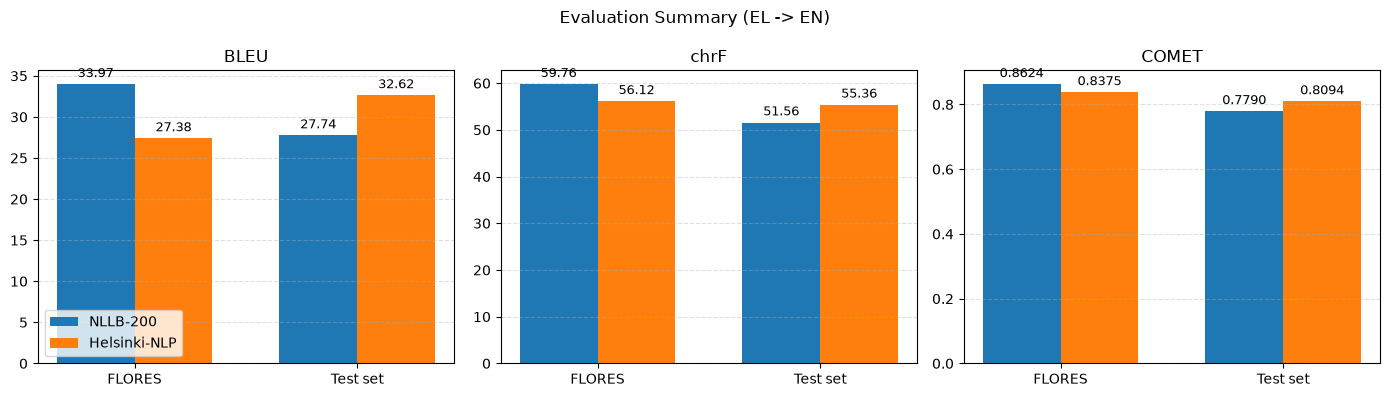

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
datasets = ["FLORES", "Test set"]
models = ["facebook/nllb-200-distilled-600M", "Helsinki-NLP/opus-mt-grk-en"]
short_names = ["NLLB-200", "Helsinki-NLP"]
x = range(len(datasets))
width = 0.35

for ax, metric in zip(axes, ["BLEU", "chrF", "COMET"]):
    for idx, (model, label) in enumerate(zip(models, short_names)):
        vals = [results_df[(results_df["Dataset"] == d) & (results_df["Model"] == model)][metric].values[0] for d in datasets]
        bars = ax.bar([p + idx * width for p in x], vals, width, label=label)
        fmt = "{:.4f}" if metric == "COMET" else "{:.2f}"
        ax.bar_label(bars, labels=[fmt.format(v) for v in vals], padding=3, fontsize=9)
    ax.set_title(metric)
    ax.set_xticks([p + width / 2 for p in x])
    ax.set_xticklabels(datasets)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].legend()
fig.suptitle("Evaluation Summary (EL -> EN)")
plt.tight_layout()
plt.savefig("evaluation_summary.png", dpi=150, bbox_inches="tight")
plt.show()